# 02. Baseline 재현 및 평가

## 공식 Baseline 구조
| 단계 | 설정 |
|---|---|
| 전처리 | Grayscale → Resize(128×128) → ToTensor (정규화·증강 없음) |
| 데이터 | train 전체 학습, 검증셋 없음 |
| 모델 | SimpleCNN (Conv 16→32, 2층 + FC), 사전학습 없음 |
| 손실 / 최적화 | CrossEntropyLoss / Adam (lr=0.001) |
| 학습 | 2 epochs |
| 예측 | argmax → 0/1 |

## Baseline 코드상의 한계
1. **검증셋 부재** → train loss 외 성능 측정 불가, 과적합 여부 판단 불가
2. **클래스 불균형 미고려** → 다수 클래스(폐렴) 편향 가능
3. **해상도 손실** → 224×224 원본을 128×128로 축소 (면적 약 1/3), 미세 병변 정보 손실 가능
4. **작은 모델 + 짧은 학습** → Conv 2층, 2 epochs, 사전학습 없음
5. **임계값 고정** → argmax(사실상 0.5 기준)로 0/1 결정. 대회 지표가 Accuracy이므로 0/1 제출 자체는 적절하나, 불균형·분포 차이 상황에서 최적 임계값이 0.5가 아닐 수 있음
6. **재현성 장치 부재** → Seed 미고정, 모델 저장 없음

## 재현 원칙: 모델·학습 설정은 그대로, 평가 장치만 추가
| 유지 | 추가 |
|---|---|
| 128×128 흑백, SimpleCNN, CrossEntropyLoss, Adam 1e-3, 2 epochs | Seed 고정, 층화 분할 검증셋(8:2), AUC·민감도·특이도·혼동행렬, 모델 저장 |

- 검증셋 분리로 학습 데이터가 80%로 줄어드나, 이후 모든 실험에서 **동일 분할(split_train/valid.csv)**을 사용하여 공정하게 비교

In [1]:
# Setup & reproducibility


# os : 폴더·파일 경로를 다루는 파이썬 기본 라이브러리
import os
# random : 파이썬 기본 무작위 함수
import random
# numpy : 숫자 배열 계산
import numpy as np
# torch : 파이토치 (딥러닝 프레임워크)
import torch

# SEED : 무작위 결과를 고정할 기준 숫자
SEED = 42

def seed_everything(seed):
    # 파이썬 기본 random 고정
    random.seed(seed)
    # 파이썬 해시값 생성 방식 고정
    os.environ["PYTHONHASHSEED"] = str(seed)
    # numpy 무작위 고정
    np.random.seed(seed)
    # 파이토치 CPU 연산 무작위 고정
    torch.manual_seed(seed)
    # 파이토치 GPU 연산 무작위 고정
    torch.cuda.manual_seed_all(seed)
    # cudnn(GPU 가속 라이브러리)이 매번 같은 계산 방식을 쓰도록 강제
    torch.backends.cudnn.deterministic = True
    # 가장 빠른 계산 방식 자동 탐색 끄기 (켜두면 실행마다 결과가 달라질 수 있음)
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# GPU를 쓸 수 있으면 "cuda", 아니면 "cpu"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
# GPU 이름 출력 (T4가 잡혔는지 확인)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# → 모든 무작위 요소를 SEED=42로 고정해 누가 실행해도 같은 결과가 나오게 하고,
#   사용할 장치(GPU/CPU)와 GPU 이름을 확인하겠다

device: cuda
GPU: Tesla T4


In [2]:
# Mount Drive & unzip data


# os : 폴더·경로를 다루는 기본 라이브러리 (런타임 재시작 후에도 이 셀만으로 실행되도록 다시 불러옴)
import os
# Colab에서 구글 드라이브에 접근하는 도구
from google.colab import drive
# 내 드라이브를 /content/drive 위치에 연결 (처음엔 로그인·권한 허용 창이 뜸)
drive.mount("/content/drive")

# PROJECT_DIR : 드라이브 안 프로젝트 폴더
PROJECT_DIR = "/content/drive/MyDrive/dacon_chest_xray"
# 하위 폴더 3개 생성 / exist_ok=True : 이미 있으면 에러 없이 넘어감
for sub in ["data", "models", "submissions"]:
    os.makedirs(os.path.join(PROJECT_DIR, sub), exist_ok=True)

# ZIP_PATH : 드라이브에 올린 압축파일 위치
ZIP_PATH = os.path.join(PROJECT_DIR, "data", "open.zip")
# DATA_DIR : 압축을 풀 Colab 로컬 위치 (드라이브보다 읽기 속도가 훨씬 빠름)
DATA_DIR = "/content/data"

# 압축파일이 있는지 확인 후 처리
if os.path.exists(ZIP_PATH):
    # -q : 조용히 / -o : 덮어쓰기 / -d : 풀 위치 지정
    !unzip -q -o "{ZIP_PATH}" -d "{DATA_DIR}"
    print("unzip done:", os.listdir(DATA_DIR))
else:
    print("zip not found → 드라이브 data 폴더를 확인하세요")
    print("현재 data 폴더:", os.listdir(os.path.join(PROJECT_DIR, "data")))


# → 드라이브를 연결해 프로젝트 폴더를 확인하고,
#   압축파일을 Colab 로컬(/content/data)에 풀어 목록을 확인하겠다

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
unzip done: ['test', 'sample_submission.csv', 'test.csv', 'train.csv', 'train']


In [3]:
# Transforms & Dataset (official baseline, modified to accept DataFrame)


# pandas : 표 데이터 / PIL.Image : 이미지 열기
import pandas as pd
from PIL import Image
# torch.nn : 신경망 층 / torch.optim : 최적화 알고리즘
import torch.nn as nn
import torch.optim as optim
# Dataset : "i번째 데이터 주세요"에 답하는 틀 / DataLoader : 데이터를 배치 단위로 묶어 전달
from torch.utils.data import Dataset, DataLoader
# transforms : 이미지 전처리 함수 모음
from torchvision import transforms

# IMG_SIZE : Baseline 입력 크기 (원본 224 → 128로 축소, 공식 설정 그대로)
IMG_SIZE = 128

# transforms.Compose : 여러 전처리를 순서대로 묶음
tf = transforms.Compose([
    # Grayscale() : 흑백 1채널로 변환 (이미 L 모드지만 안전장치)
    transforms.Grayscale(),
    # Resize : 128×128로 크기 변경
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    # ToTensor() : 이미지(0~255) → 파이토치 텐서(0~1), 모양 (1, 128, 128)
    transforms.ToTensor()
])

# 학습·검증용 Dataset
# [원본과 차이] 원본은 csv 경로를 받았지만, 여기선 DataFrame을 받음 → 검증셋으로 나눈 표를 그대로 넣기 위해
class TrainCSV(Dataset):
    def __init__(self, df, root_dir):
        # 파일 이름 목록과 정답 목록을 리스트로 저장
        self.files = df["file_name"].tolist()
        self.labels = df["label"].astype(int).tolist()
        # root : 이미지 폴더 경로 / tf : 전처리
        self.root, self.tf = root_dir, tf
    # 데이터 개수 반환 ("총 몇 개야?")
    def __len__(self):
        return len(self.files)
    # i번째 데이터 반환 ("i번째 줘")
    def __getitem__(self, i):
        # .convert("L") : 흑백으로 열기
        img = Image.open(os.path.join(self.root, self.files[i])).convert("L")
        x = self.tf(img)
        y = self.labels[i]
        return x, y

# 테스트용 Dataset (정답이 없으므로 이미지만 반환)
class TestCSV(Dataset):
    def __init__(self, df, root_dir):
        self.files = df["file_name"].tolist()
        self.root, self.tf = root_dir, tf
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(self.root, self.files[i])).convert("L")
        return self.tf(img)


# → 공식 Baseline과 같은 전처리(흑백·128×128·텐서)를 정의하고,
#   학습/검증용과 테스트용 Dataset을 DataFrame을 받는 형태로 만들겠다

In [4]:
# Stratified train/validation split & DataLoaders


# train_test_split : 데이터를 학습용/검증용으로 나눠주는 함수
from sklearn.model_selection import train_test_split

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

# test_size=0.2 : 20%를 검증용으로
# stratify=label : 정상:폐렴 비율(25.7:74.3)을 학습·검증 양쪽에 똑같이 유지
# random_state=SEED : 매번 같은 방식으로 나뉘도록 고정
# shuffle=True(기본값) : 섞어서 나눔 → 파일이 클래스 순으로 정렬된 문제 해결
tr_df, val_df = train_test_split(
    train_df, test_size=0.2, stratify=train_df["label"], random_state=SEED
)

# 분할 결과 확인 : 개수와 클래스 비율
for name, d in [("train", tr_df), ("valid", val_df)]:
    ratio = (d["label"].value_counts(normalize=True).sort_index() * 100).round(1).tolist()
    print(f"{name}: {len(d)}장 | 정상/폐렴 비율(%): {ratio}")

# 분할 결과를 드라이브에 저장 → 이후 모든 개선 실험에서 똑같은 분할을 쓰기 위해
tr_df.to_csv(os.path.join(PROJECT_DIR, "data", "split_train.csv"), index=False)
val_df.to_csv(os.path.join(PROJECT_DIR, "data", "split_valid.csv"), index=False)

TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train")
TEST_IMG_DIR = os.path.join(DATA_DIR, "test")

# torch.Generator().manual_seed : DataLoader가 섞는 순서까지 고정 (재현성)
g = torch.Generator().manual_seed(SEED)

# batch_size=32 : 한 번에 32장씩 (공식 설정) / shuffle=True : 학습 데이터는 매 에폭 섞기
train_loader = DataLoader(TrainCSV(tr_df, TRAIN_IMG_DIR), batch_size=32, shuffle=True, generator=g)
# 검증·테스트는 섞지 않음 → 예측 결과와 파일 이름 순서를 맞추기 위해
val_loader = DataLoader(TrainCSV(val_df, TRAIN_IMG_DIR), batch_size=64, shuffle=False)
test_loader = DataLoader(TestCSV(test_df, TEST_IMG_DIR), batch_size=64, shuffle=False)

# 배치 하나를 꺼내서 모양 확인
x, y = next(iter(train_loader))
# (32, 1, 128, 128) : 32장 × 1채널(흑백) × 128 × 128
print("batch x:", x.shape, "| batch y:", y.shape)
print("pixel range:", round(x.min().item(), 2), "~", round(x.max().item(), 2))


# → train을 클래스 비율을 유지한 채 8:2로 섞어 나누고 그 분할을 저장한 뒤,
#   학습·검증·테스트 DataLoader를 만들어 배치 모양을 확인하겠다

train: 4172장 | 정상/폐렴 비율(%): [25.7, 74.3]
valid: 1044장 | 정상/폐렴 비율(%): [25.7, 74.3]
batch x: torch.Size([32, 1, 128, 128]) | batch y: torch.Size([32])
pixel range: 0.0 ~ 1.0


In [5]:
# SimpleCNN model (official baseline, unchanged)


# nn.Module : 파이토치 모든 신경망의 기본 틀 (이걸 상속해서 모델을 만듦)
class SimpleCNN(nn.Module):
    def __init__(self):
        # super().__init__() : 부모 클래스(nn.Module)의 초기 설정 실행 (필수)
        super().__init__()
        # nn.Sequential : 여러 층을 순서대로 묶음
        self.conv = nn.Sequential(
            # Conv2d(입력채널 1, 출력채널 16, 필터크기 3) : 흑백 이미지에서 16가지 특징 추출
            # padding=1 : 테두리를 1칸 채워서 크기 유지 (128 → 128)
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # (16, 64, 64)
            # 16개 특징 → 32개 특징 / MaxPool2d(2) : 가로세로 절반으로 축소
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)    # (32, 32, 32)
        )
        # Flatten : (32, 32, 32) → 32×32×32 = 32,768개 숫자 한 줄로 펼침
        # Linear(32768, 2) : 펼친 특징으로 [정상 점수, 폐렴 점수] 2개 출력
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(32 * 32 * 32, 2))

    # forward : 데이터가 모델을 통과하는 순서 (conv → fc)
    def forward(self, x):
        return self.fc(self.conv(x))

# 모델 가중치 초기값도 매번 같게 → 모델 만들기 직전에 Seed 다시 고정
seed_everything(SEED)
# .to(device) : 모델을 GPU로 옮김
model = SimpleCNN().to(device)

# CrossEntropyLoss : 분류 문제 기본 손실함수 (클래스 가중치 없음, 공식 설정)
criterion = nn.CrossEntropyLoss()
# Adam, lr=1e-3 (=0.001) : 공식 설정 그대로
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 학습 가능한 파라미터(가중치) 개수 확인
# p.numel() : 텐서 안 숫자 개수 / requires_grad : 학습 대상인지 여부
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"trainable params: {n_params:,}")


# → 공식 Baseline과 똑같은 SimpleCNN·손실함수·최적화 설정을 만들고,
#   모델 구조와 학습할 가중치 개수를 확인하겠다

SimpleCNN(
  (conv): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=2, bias=True)
  )
)
trainable params: 70,338


In [6]:
# Evaluation function & training loop (2 epochs)


# sklearn.metrics : 성능 지표 계산 함수 모음
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, f1_score

# 검증 데이터로 성능을 계산하는 함수 (학습에는 전혀 영향 없음)
def evaluate(model, loader):
    # model.eval() : 평가 모드 (학습용 동작을 끔)
    model.eval()
    probs, labels = [], []
    # torch.no_grad() : 기울기 계산 끄기 → 메모리 절약, 가중치 업데이트 없음
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits = model(x)
            # softmax : 점수 → 확률 (두 클래스 합 = 1) / [:, 1] : 폐렴일 확률만 꺼냄
            p = torch.softmax(logits, dim=1)[:, 1]
            probs.extend(p.cpu().numpy())
            labels.extend(y.numpy())
    probs, labels = np.array(probs), np.array(labels)
    # argmax와 같은 효과 : 폐렴 확률 0.5 이상이면 1
    preds = (probs >= 0.5).astype(int)
    return {
        "acc": accuracy_score(labels, preds),
        # AUC : 확률의 "순서"로 정상/폐렴을 얼마나 잘 구분하는지 (임계값과 무관)
        "auc": roc_auc_score(labels, probs),
        "probs": probs, "preds": preds, "labels": labels,
    }

EPOCHS = 2
# history : 에폭마다 결과를 저장해 두는 리스트 (나중에 표·그래프용)
history = []
# DataLoader 섞는 순서도 처음부터 다시 고정 (셀 4에서 배치 하나를 미리 꺼냈기 때문)
g.manual_seed(SEED)

for ep in range(EPOCHS):
    # model.train() : 학습 모드
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        # 1) 순전파 : 이미지 → 점수
        logits = model(x)
        # 2) 손실 계산 : 점수와 정답 비교
        loss = criterion(logits, y)
        # 3) 이전 기울기 초기화 → 4) 역전파(기울기 계산) → 5) 가중치 업데이트
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # 배치 손실 × 배치 크기 → 에폭 전체 평균을 구하기 위해 누적
        running += loss.item() * x.size(0)
    train_loss = running / len(train_loader.dataset)

    # 에폭이 끝날 때마다 검증 성능 확인 (평가만 할 뿐 학습에는 사용 안 함)
    val = evaluate(model, val_loader)
    history.append({"epoch": ep + 1, "train_loss": train_loss, "val_acc": val["acc"], "val_auc": val["auc"]})
    print(f"Epoch {ep+1} | train loss {train_loss:.4f} | val acc {val['acc']:.4f} | val auc {val['auc']:.4f}")


# → 검증 성능을 계산하는 함수를 만들고, 공식 설정대로 2 에폭 학습하면서
#   에폭마다 train loss와 검증 Accuracy·AUC를 기록하겠다

Epoch 1 | train loss 0.3137 | val acc 0.9234 | val auc 0.9758
Epoch 2 | train loss 0.1660 | val acc 0.9454 | val auc 0.9832


[Baseline validation result]
Accuracy    : 0.9454  (전부 폐렴으로 찍으면 0.7433)
AUC         : 0.9832
Sensitivity : 0.9433  (폐렴 776명 중 732명 탐지, 44명 놓침)
Specificity : 0.9515  (정상 268명 중 255명 정상 판정, 13명 오진)
F1-score    : 0.9625


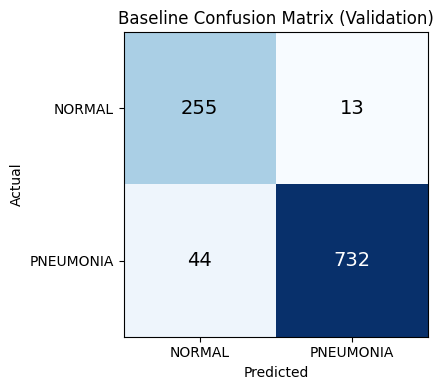

In [7]:
# Final validation metrics & confusion matrix


import matplotlib.pyplot as plt

val = evaluate(model, val_loader)
# confusion_matrix(...).ravel() : 2×2 표를 [TN, FP, FN, TP] 순서로 풀어냄
# TN : 정상을 정상으로 / FP : 정상을 폐렴으로(오진) / FN : 폐렴을 정상으로(놓침) / TP : 폐렴을 폐렴으로
tn, fp, fn, tp = confusion_matrix(val["labels"], val["preds"]).ravel()

# Sensitivity(민감도) : 실제 폐렴 중 폐렴으로 맞힌 비율 → 낮으면 환자를 놓침
sensitivity = tp / (tp + fn)
# Specificity(특이도) : 실제 정상 중 정상으로 맞힌 비율 → 낮으면 정상인을 오진
specificity = tn / (tn + fp)
f1 = f1_score(val["labels"], val["preds"])
# 비교 기준 : 전부 "폐렴"이라고 찍었을 때의 정확도
all_pneumonia_acc = val["labels"].mean()

print("[Baseline validation result]")
print(f"Accuracy    : {val['acc']:.4f}  (전부 폐렴으로 찍으면 {all_pneumonia_acc:.4f})")
print(f"AUC         : {val['auc']:.4f}")
print(f"Sensitivity : {sensitivity:.4f}  (폐렴 {tp + fn}명 중 {tp}명 탐지, {fn}명 놓침)")
print(f"Specificity : {specificity:.4f}  (정상 {tn + fp}명 중 {tn}명 정상 판정, {fp}명 오진)")
print(f"F1-score    : {f1:.4f}")

# 혼동행렬 시각화
cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(4.5, 4))
# imshow : 숫자 표를 색깔 칸으로 / cmap="Blues" : 값이 클수록 진한 파랑
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        # 칸마다 숫자 표시 / 진한 칸은 흰 글씨로
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
ax.set_xticks([0, 1]); ax.set_xticklabels(["NORMAL", "PNEUMONIA"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["NORMAL", "PNEUMONIA"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Baseline Confusion Matrix (Validation)")
plt.tight_layout()
plt.show()


# → 학습이 끝난 Baseline 모델로 검증셋을 평가해 Accuracy·AUC·민감도·특이도·F1을 계산하고,
#   "전부 폐렴" 기준과 비교한 뒤 혼동행렬을 그림으로 보여주겠다

In [8]:
# Save model


# MODEL_DIR : 드라이브의 models 폴더 (Colab이 끊겨도 남도록 드라이브에 저장)
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
MODEL_PATH = os.path.join(MODEL_DIR, "baseline_simplecnn.pth")

# model.state_dict() : 모델의 가중치만 사전(dict) 형태로 꺼냄 (구조는 코드에 있으니 가중치만 저장)
# torch.save : 파일로 저장 / .pth : 파이토치 모델 파일 확장자 관례
torch.save(model.state_dict(), MODEL_PATH)
print("saved:", MODEL_PATH)

# 저장이 제대로 됐는지 확인 : 새 모델을 만들어 가중치를 불러온 뒤 같은 결과가 나오는지 비교
loaded = SimpleCNN().to(device)
# torch.load : 파일 읽기 / map_location=device : 저장할 때와 다른 장치여도 현재 장치로 불러옴
# load_state_dict : 읽은 가중치를 모델에 덮어씀
loaded.load_state_dict(torch.load(MODEL_PATH, map_location=device))
check = evaluate(loaded, val_loader)
print(f"reloaded model val acc: {check['acc']:.4f} | val auc: {check['auc']:.4f}")


# → 학습된 Baseline 가중치를 드라이브에 저장하고,
#   다시 불러온 모델이 같은 검증 성능을 내는지 확인하겠다

saved: /content/drive/MyDrive/dacon_chest_xray/models/baseline_simplecnn.pth
reloaded model val acc: 0.9454 | val auc: 0.9832


In [9]:
# Test prediction & submission file


model.eval()
test_probs = []
with torch.no_grad():
    # test_loader는 정답이 없어서 이미지(x)만 나옴
    for x in test_loader:
        x = x.to(device)
        # 폐렴일 확률
        p = torch.softmax(model(x), dim=1)[:, 1]
        test_probs.extend(p.cpu().numpy())
test_probs = np.array(test_probs)
# 임계값 0.5 → 0/1 (공식 Baseline의 argmax와 같은 결과)
test_preds = (test_probs >= 0.5).astype(int)

# 제출 양식 불러와서 label 칸에 예측값 채우기
submission = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
# 순서 확인 : 제출 양식 파일 순서와 test.csv 순서가 같아야 예측이 올바른 이미지에 매칭됨
assert (submission["file_name"].values == test_df["file_name"].values).all(), "파일 순서 불일치!"
submission["label"] = test_preds

# 드라이브 submissions 폴더에 저장
SUB_PATH = os.path.join(PROJECT_DIR, "submissions", "baseline_simplecnn.csv")
submission.to_csv(SUB_PATH, index=False)

print("saved:", SUB_PATH)
print(submission.head())
# 예측 분포 확인 : 너무 한쪽으로 쏠렸는지
print("\n[Test prediction count]")
print(submission["label"].value_counts().sort_index())


# → 테스트 이미지 624장의 폐렴 확률을 구해 0.5 기준으로 0/1로 바꾸고,
#   제출 양식에 채워 드라이브에 csv로 저장하겠다

saved: /content/drive/MyDrive/dacon_chest_xray/submissions/baseline_simplecnn.csv
       file_name  label
0  test_0001.png      0
1  test_0002.png      0
2  test_0003.png      1
3  test_0004.png      1
4  test_0005.png      1

[Test prediction count]
label
0    310
1    314
Name: count, dtype: int64


In [10]:
# Diagnose: validation vs test prediction distribution


# 1) 검증셋 예측 분포 : 정상(0)으로 예측한 이미지가 있는지
print("[Validation prediction count]")
print(pd.Series(val["preds"]).value_counts().sort_index())

# 2) 검증 vs 테스트 폐렴 확률 분포 비교
# np.percentile : 하위 5%, 50%(중앙값), 95% 지점 값
for name, p in [("valid", val["probs"]), ("test", test_probs)]:
    q5, q50, q95 = np.percentile(p, [5, 50, 95])
    print(f"{name:5s} prob | min {p.min():.3f} | 5% {q5:.3f} | median {q50:.3f} | 95% {q95:.3f} | max {p.max():.3f}")

# 3) 테스트 이미지 속성 확인 : 학습 이미지(224×224, L)와 같은지
from collections import Counter
t_sizes, t_modes, t_means = [], [], []
for fname in test_df["file_name"]:
    with Image.open(os.path.join(TEST_IMG_DIR, fname)) as img:
        t_sizes.append(img.size)
        t_modes.append(img.mode)
        # 흑백으로 바꿔 평균 밝기 계산 (0~255)
        t_means.append(np.array(img.convert("L")).mean())
print("\n[Test image size]", Counter(t_sizes).most_common(3))
print("[Test image mode]", Counter(t_modes))

# 4) 학습 vs 테스트 평균 밝기 비교 (학습은 앞 600장만 샘플로)
tr_means = [np.array(Image.open(os.path.join(TRAIN_IMG_DIR, f)).convert("L")).mean()
            for f in train_df["file_name"].sample(600, random_state=SEED)]
print(f"\nmean brightness | train {np.mean(tr_means):.1f} | test {np.mean(t_means):.1f}")


# → 검증셋에서도 전부 폐렴으로 예측했는지 확인하고,
#   검증·테스트의 폐렴 확률 분포와 테스트 이미지 속성(크기·채널·밝기)을 학습 데이터와 비교하겠다

[Validation prediction count]
0    299
1    745
Name: count, dtype: int64
valid prob | min 0.000 | 5% 0.002 | median 0.979 | 95% 1.000 | max 1.000
test  prob | min 0.000 | 5% 0.006 | median 0.503 | 95% 0.984 | max 0.998

[Test image size] [((1112, 736), 3), ((1088, 576), 2), ((1368, 904), 2)]
[Test image mode] Counter({'L': 624})

mean brightness | train 88.7 | test 121.0


## 📌 Mission 1 결과 정리

### 1. Baseline 성능 기록

| 구분 | Accuracy | AUC | Sensitivity | Specificity | F1 |
|---|---|---|---|---|---|
| 검증셋 (1,044장) | 0.9454 | 0.9832 | 0.9433 | 0.9515 | 0.9625 |
| 리더보드 (테스트 624장) | 0.7468 | - | - | - | - |
| (참고) 전부 폐렴 예측 | 0.7433 (검증) / 0.625 (리더보드) | - | 1.0 | 0.0 | - |

- 에폭별 Val AUC: 0.9758 → 0.9832 (2 에폭에서도 상승 중)
- 검증셋 오류: 놓친 폐렴(FN) 44명, 오진한 정상(FP) 13명

### 2. 문제점 도출

**① 학습·테스트 분포 차이로 검증 성능이 실제 성능을 대변하지 못함 (가장 큰 문제)**
- 학습 이미지는 224×224로 가공(검은 여백 포함, 평균 밝기 88.7), 테스트 이미지는 원본 크기 그대로(여백 없음, 평균 밝기 121.0)
- 폐렴 확률 중앙값: 검증 0.979 → 테스트 0.503 → 테스트에서 확신도가 크게 떨어짐
- 검증 Accuracy 0.9454 대비 리더보드 0.7468 → 약 19.9%p 하락

**② 테스트에서 환자를 놓치는 오류(False Negative) 증가 가능성**
- 테스트에서 정상 예측 비율 49.7%로, 실제 정상 비율(약 37.5%)보다 과도함
- 의료 진단 보조 관점에서 가장 위험한 오류 유형

**③ 지름길 학습 위험**
- EDA에서 폐렴 이미지일수록 검은 영역이 넓음을 확인 (정상 17.6% vs 폐렴 31.5%)
- 이 단서는 테스트 이미지에 존재하지 않으므로, 모델이 의존했다면 테스트 성능 하락의 원인이 됨

**④ 학습 부족 및 모델 용량 한계**
- 2 epochs에서 AUC가 아직 상승 중, Conv 2층(파라미터 약 7만 개), 사전학습 없음
- 128×128 축소로 미세 병변 정보 손실 가능

### 3. 개선 방향 가설

| 가설 | 근거 | 기대 효과 |
|---|---|---|
| **H1. 학습 이미지의 검은 여백을 Crop하면 테스트 성능이 오르고 검증-테스트 격차가 줄어든다** | 문제점 ①, ③ | 지름길 단서 제거 + 학습·테스트 이미지 형태 통일 |
| **H2. 밝기·대비 증강을 적용하면 테스트 이미지에서의 확신도가 회복된다** | 문제점 ① (밝기 88.7 vs 121.0) | 밝기 차이에 강건한 모델 |
| **H3. ImageNet 사전학습 모델 + 224 해상도로 바꾸면 구분 능력이 오른다** | 문제점 ④ | 적은 데이터로도 풍부한 특징 학습 |
| **H4. 클래스 가중치 손실을 적용하면 민감도·특이도 균형이 개선된다** | Mission 0 가설, 클래스 불균형 2.89배 | 다수 클래스 편향 완화 |

- 우선순위: **H1 → H2** (Baseline의 가장 큰 문제인 분포 차이를 직접 겨냥) → H3 → H4
- 검증 방식: 모든 실험은 동일 분할(`split_train/valid.csv`) 사용, **검증 점수와 리더보드 점수를 함께 기록**하여 격차가 줄어드는지 확인